In [1]:
%pip install tensorflow datasets scikit-learn matplotlib pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
#checking version
import sys
print("Python version:", sys.version)

import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
TensorFlow version: 2.22.0-rc0
Available GPUs: []


In [3]:
#load dataset
from datasets import load_dataset
dataset=load_dataset("Project-AgML/tomato_leaf_disease",split="train")
print(dataset)
print(dataset.column_names)

Dataset({
    features: ['image', 'label'],
    num_rows: 11000
})
['image', 'label']


In [4]:
#inspect plant  disease
from collections import Counter

print("Dataset size:", len(dataset))

label_feature = dataset.features["label"]

print("\nLabel names:")
print(label_feature.names)

print("\nImages per class:")
counts = Counter(dataset["label"])

for label_id, count in sorted(counts.items()):
    label_name = label_feature.int2str(label_id)
    print(f"{label_name}: {count}")

Dataset size: 11000

Label names:
['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Leaf Mold', 'Septoria Leaf Spot', 'Spider Mites Two-spotted Spider Mite', 'Target Spot', 'Tomato Mosaic Virus', 'Tomato Yellow Leaf Curl Virus']

Images per class:
Bacterial Spot: 1100
Early Blight: 1100
Healthy: 1100
Late Blight: 1100
Leaf Mold: 1100
Septoria Leaf Spot: 1100
Spider Mites Two-spotted Spider Mite: 1100
Target Spot: 1100
Tomato Mosaic Virus: 1100
Tomato Yellow Leaf Curl Virus: 1100


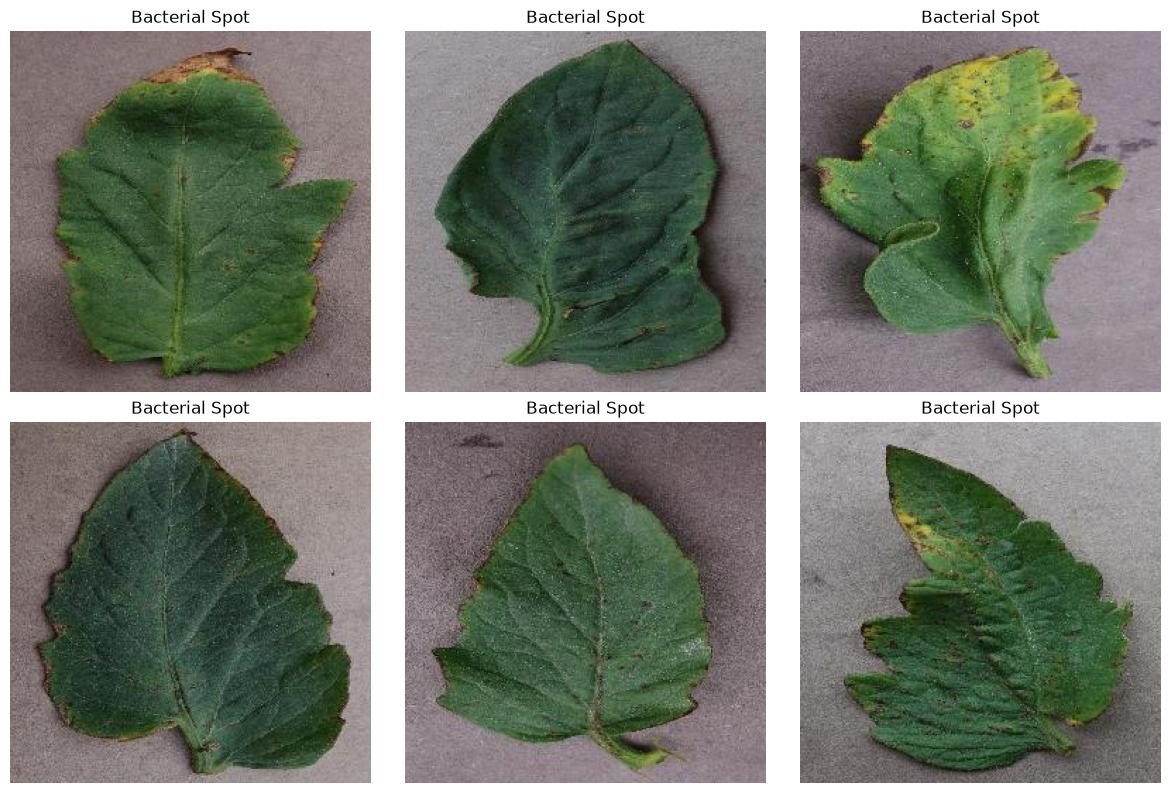

In [5]:
#display sample leaf images
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    sample = dataset[i]
    ax.imshow(sample["image"])
    ax.set_title(label_feature.int2str(sample["label"]))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Split into 80% training and 20% temporary data
split_1 = dataset.train_test_split(
    test_size=0.20,
    seed=42,
    stratify_by_column="label"
)

train_data = split_1["train"]
temp_data = split_1["test"]

# Split temporary data equally into validation and test sets
split_2 = temp_data.train_test_split(
    test_size=0.50,
    seed=42,
    stratify_by_column="label"
)

val_data = split_2["train"]
test_data = split_2["test"]

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

Training images: 8800
Validation images: 1100
Testing images: 1100


In [7]:
# Prepare images for the model
import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 16

print("TensorFlow version:", tf.__version__)
print("CPU devices:", tf.config.list_physical_devices("CPU"))

TensorFlow version: 2.22.0-rc0
CPU devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [8]:
from collections import Counter
from PIL import Image

class_names = label_feature.names
NUM_CLASSES = len(class_names)

def prepare_example(example):
    image = example["image"].convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    image = np.array(image, dtype=np.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, int(example["label"])

def make_dataset(hf_dataset, shuffle=False):
    def generator():
        for example in hf_dataset:
            yield prepare_example(example)

    output_signature = (
        tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int64)
    )

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=output_signature
    )

    if shuffle:
        ds = ds.shuffle(1000, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(1)

train_ds = make_dataset(train_data, shuffle=True)
val_ds = make_dataset(val_data)
test_ds = make_dataset(test_data)

print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)
print("Datasets prepared!")

Number of classes: 10
Classes: ['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Leaf Mold', 'Septoria Leaf Spot', 'Spider Mites Two-spotted Spider Mite', 'Target Spot', 'Tomato Mosaic Virus', 'Tomato Yellow Leaf Curl Virus']
Datasets prepared!


In [9]:
# Load the pretrained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          12,810 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
# train the models
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_tomato_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3


C:\Users\Gayathri R\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


550/550 ━━━━━━━━━━━━━━━━━━━━ 170s 298ms/step - accuracy: 0.7618 - loss: 0.7804 - val_accuracy: 0.8591 - val_loss: 0.4812
Epoch 2/3
550/550 ━━━━━━━━━━━━━━━━━━━━ 185s 333ms/step - accuracy: 0.8772 - loss: 0.4019 - val_accuracy: 0.8945 - val_loss: 0.3742
Epoch 3/3
550/550 ━━━━━━━━━━━━━━━━━━━━ 139s 250ms/step - accuracy: 0.9053 - loss: 0.3141 - val_accuracy: 0.8900 - val_loss: 0.3403


In [11]:
#check results
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

69/69 ━━━━━━━━━━━━━━━━━━━━ 20s 289ms/step - accuracy: 0.8755 - loss: 0.3867
Test loss: 0.3867
Test accuracy: 87.55%


69/69 ━━━━━━━━━━━━━━━━━━━━ 16s 218ms/step
                                      precision    recall  f1-score   support

                      Bacterial Spot       0.87      0.86      0.87       110
                        Early Blight       0.88      0.61      0.72       110
                             Healthy       0.93      0.97      0.95       110
                         Late Blight       0.86      0.89      0.88       110
                           Leaf Mold       0.87      0.89      0.88       110
                  Septoria Leaf Spot       0.81      0.83      0.82       110
Spider Mites Two-spotted Spider Mite       0.93      0.83      0.88       110
                         Target Spot       0.74      0.91      0.81       110
                 Tomato Mosaic Virus       0.93      0.98      0.96       110
       Tomato Yellow Leaf Curl Virus       0.98      0.98      0.98       110

                            accuracy                           0.88      1100
                    

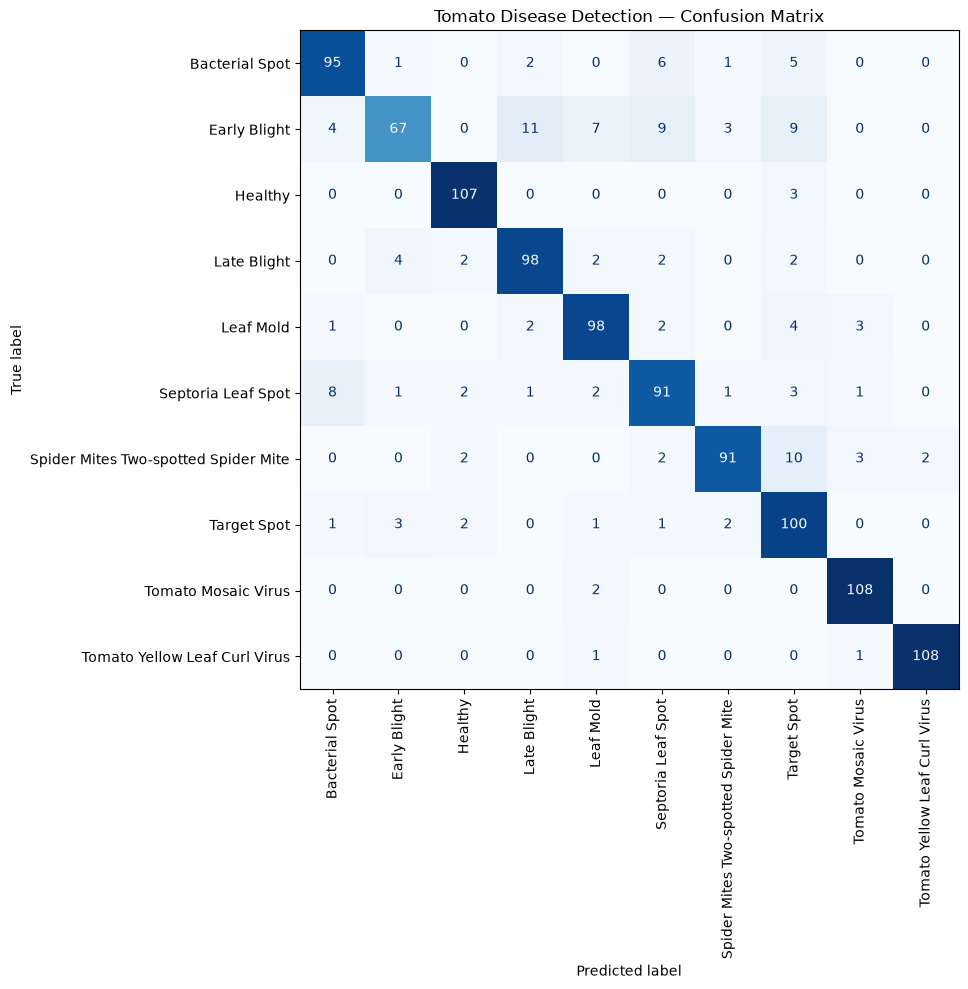

In [12]:
# Generate evaluation metrics
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Get true labels and model predictions
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Print precision, recall, and F1-score
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Tomato Disease Detection — Confusion Matrix")
plt.tight_layout()
plt.show()

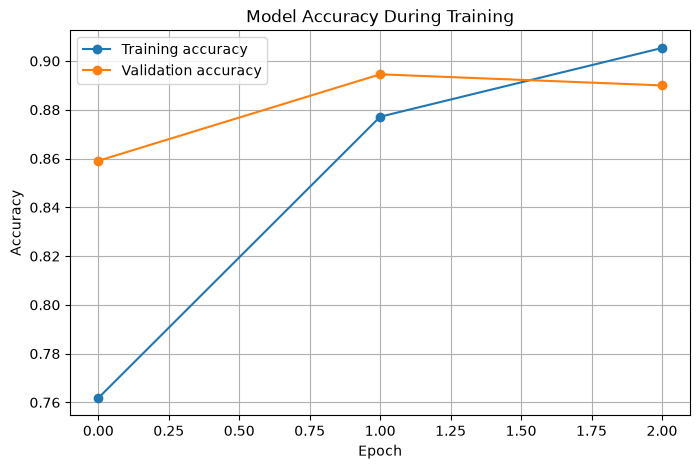

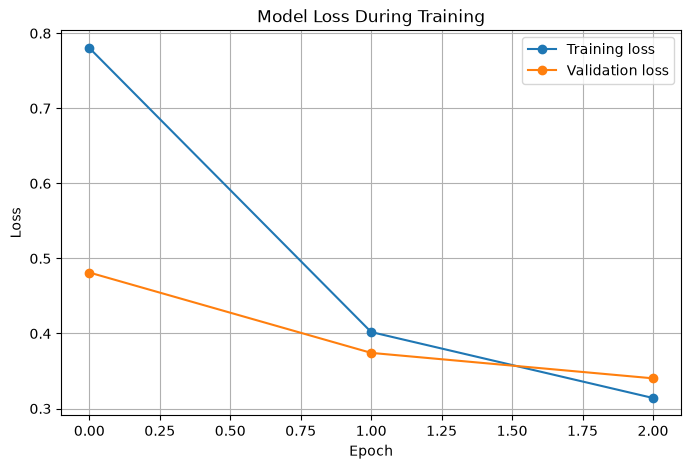

In [13]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy During Training")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss During Training")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Save your trained model
from pathlib import Path

Path("models").mkdir(exist_ok=True)

model.save("models/tomato_disease_model.keras")

with open("models/class_names.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(class_names))

print("Model and class names saved successfully!")

Model and class names saved successfully!


In [16]:
#  explainable ai with grad-cam function
def make_gradcam_heatmap(image_array, model, base_model):
    feature_extractor = tf.keras.Model(
        inputs=base_model.inputs,
        outputs=base_model.get_layer("out_relu").output
    )

    with tf.GradientTape() as tape:
        conv_output = feature_extractor(image_array, training=False)

        # Pass extracted features through the trained classification head
        x = model.layers[2](conv_output)
        x = model.layers[3](x, training=False)
        predictions = model.layers[4](x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(conv_output[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), int(class_index.numpy())

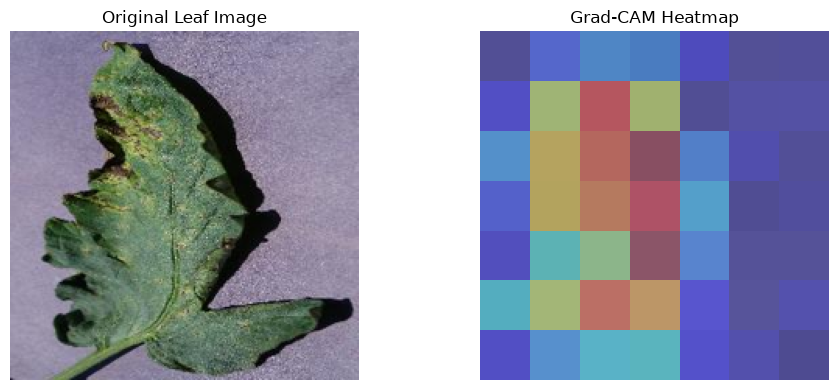

Predicted disease: Septoria Leaf Spot
Confidence score: 84.04%


In [17]:
# visualization
image_batch, label_batch = next(iter(test_ds))
image_array = image_batch[0:1]

heatmap, predicted_index = make_gradcam_heatmap(
    image_array, model, base_model
)

original_image = (image_array[0].numpy() + 1) * 127.5
original_image = np.clip(original_image, 0, 255).astype("uint8")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

probabilities = model.predict(image_array, verbose=0)[0]

print("Predicted disease:", class_names[predicted_index])
print(f"Confidence score: {probabilities[predicted_index]:.2%}")

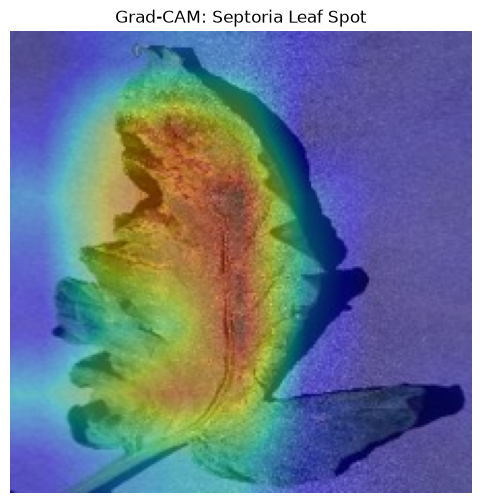

In [18]:
# Improve the Grad-CAM visualization
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Resize heatmap to match the leaf image
heatmap_resized = cv2.resize(
    heatmap,
    (original_image.shape[1], original_image.shape[0])
)

# Display the heatmap over the leaf image
plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM: {class_names[predicted_index]}")
plt.axis("off")
plt.show()

In [19]:
# Evaluate individual disease classes
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

                                      precision    recall  f1-score   support

                      Bacterial Spot       0.87      0.86      0.87       110
                        Early Blight       0.88      0.61      0.72       110
                             Healthy       0.93      0.97      0.95       110
                         Late Blight       0.86      0.89      0.88       110
                           Leaf Mold       0.87      0.89      0.88       110
                  Septoria Leaf Spot       0.81      0.83      0.82       110
Spider Mites Two-spotted Spider Mite       0.93      0.83      0.88       110
                         Target Spot       0.74      0.91      0.81       110
                 Tomato Mosaic Virus       0.93      0.98      0.96       110
       Tomato Yellow Leaf Curl Virus       0.98      0.98      0.98       110

                            accuracy                           0.88      1100
                           macro avg       0.88      0.88     